##Análisis de cobertura minera en Huepetuhe (capitulo 1)

PARTE 1. Prueba con esa-worldcover en Planetary-computer

Primero debe descargar el archivo .shp del área de estudio; se puede obtener de este drive: https://drive.google.com/drive/folders/13iwoURBlOjHKPnEHj7kD8s4TBB3s-zD7?hl=es

In [ ]:
!pip install rioxarray rasterio planetary-computer pystac-client cartopy geopandas matplotlib -q

In [ ]:
import numpy as np
import xarray as xr
import rasterio
import rioxarray
import geopandas as gpd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

In [ ]:
import os
import requests
import numpy as np
import rioxarray
import pystac_client
import planetary_computer
from rasterio.enums import Resampling

In [ ]:
shp = gpd.read_file("/content/Distrito_Huepetuhe.shp").to_crs("EPSG:4326") # archivo.shp --> área de estudio
BBOX = shp.total_bounds.tolist()
print(BBOX)


[-70.99373448099993, -13.192389980999963, -70.35273822999994, -12.804878187999975]


In [ ]:
FECHAS = "2025-07-01/2025-09-30"   # periodo de fecha a seleccionar
ANIO_WC = 2021                      # año del mapa WorldCover (para realizar la prueba, posteriormente se realizará con MapBiomas)

os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"
os.environ["GDAL_HTTP_MERGE_CONSECUTIVE_RANGES"] = "YES"
os.environ["VSI_CACHE"] = "TRUE"

In [ ]:
catalogo = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1") #se utiliza la base de datos satelitales de PlanetaryComputer

ids = [c.id for c in catalogo.get_collections()]
print(len(ids), "colecciones en el catálogo")
for c in ["esa-worldcover", "sentinel-2-l2a", "landsat-c2-l2"]:
    print(c, c in ids)

140 colecciones en el catálogo
esa-worldcover True
sentinel-2-l2a True
landsat-c2-l2 True


In [ ]:
items_wc = catalogo.search(collections=["esa-worldcover"], bbox=BBOX).item_collection()
print(len(items_wc), "items")
for it in items_wc:
    print(it.id, list(it.assets))

2 items
ESA_WorldCover_10m_2021_v200_S15W072 ['map', 'tilejson', 'input_quality', 'rendered_preview']
ESA_WorldCover_10m_2020_v100_S15W072 ['map', 'tilejson', 'input_quality', 'rendered_preview']


In [ ]:
%%time
item_wc = [it for it in items_wc if str(ANIO_WC) in it.id]
assert item_wc, "Ningún id contiene el año indicado; revisa la salida de la celda anterior"
item_wc = planetary_computer.sign(item_wc[0])

wc = (
    rioxarray.open_rasterio(item_wc.assets["map"].href)
    .squeeze("band", drop=True)
    .rio.clip_box(*BBOX)
    .load()
)
print(wc.rio.crs, wc.rio.resolution(), wc.shape)

EPSG:4326 (8.333333333333402e-05, -8.333333333333356e-05) (4651, 7693)
CPU times: user 69.4 ms, sys: 21.7 ms, total: 91.1 ms
Wall time: 2.48 s


 10  Árboles               90.9 %
 20  Arbustos               0.0 %
 30  Pastizal               3.2 %
 40  Cultivos               0.0 %
 50  Urbano                 0.1 %
 60  Suelo desnudo/ralo     4.1 %
 80  Agua                   1.8 %
 90  Humedal herbáceo       0.0 %


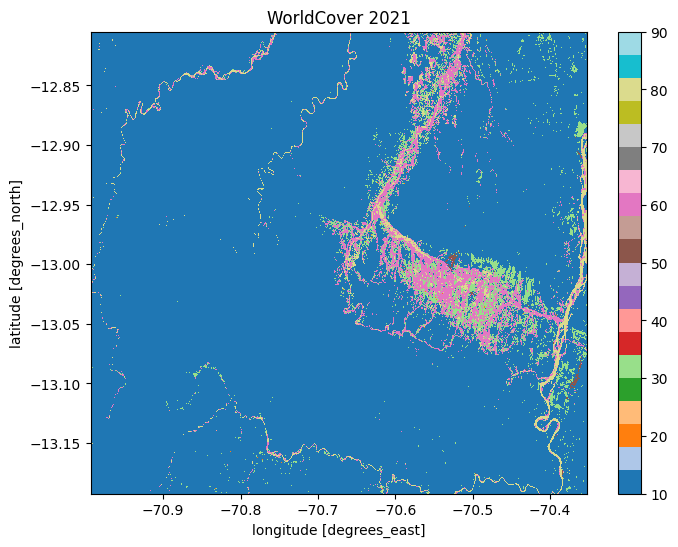

In [ ]:
CLASES = {
    10: "Árboles", 20: "Arbustos", 30: "Pastizal", 40: "Cultivos", 50: "Urbano",
    60: "Suelo desnudo/ralo", 70: "Nieve/hielo", 80: "Agua", 90: "Humedal herbáceo",
    95: "Manglar", 100: "Musgo/líquenes",
}

codigos, cuentas = np.unique(wc.values, return_counts=True)
for cod, k in zip(codigos, cuentas):
    print(f"{cod:>3}  {CLASES.get(int(cod), '?'):<20} {100 * k / cuentas.sum():5.1f} %")

wc.plot(cmap="tab20", figsize=(8, 6))
plt.title(f"WorldCover {ANIO_WC}")
plt.show()

  0  ?                     48.9 %
 10  Árboles               44.9 %
 20  Arbustos               0.0 %
 30  Pastizal               2.1 %
 40  Cultivos               0.0 %
 50  Urbano                 0.0 %
 60  Suelo desnudo/ralo     3.1 %
 80  Agua                   0.9 %
 90  Humedal herbáceo       0.0 %


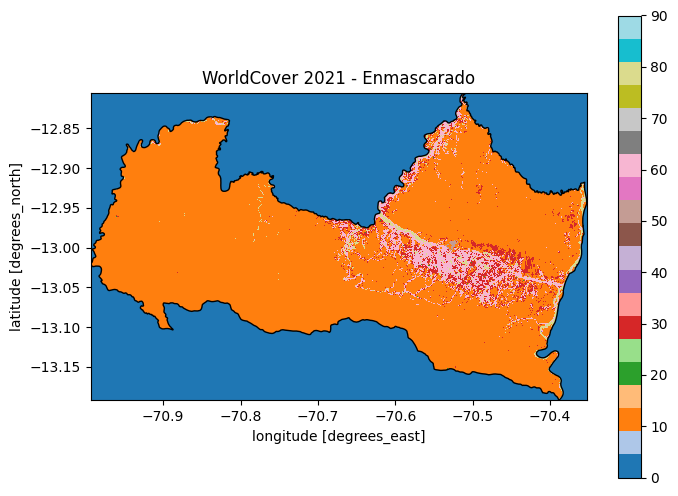

In [ ]:
CLASES = {
    10: "Árboles", 20: "Arbustos", 30: "Pastizal", 40: "Cultivos", 50: "Urbano",
    60: "Suelo desnudo/ralo", 70: "Nieve/hielo", 80: "Agua", 90: "Humedal herbáceo",
    95: "Manglar", 100: "Musgo/líquenes",
}
if wc.rio.crs is None:
    wc = wc.rio.write_crs("EPSG:4326")

shp_reproyectado = shp.to_crs(wc.rio.crs)
wc_enmascarado = wc.rio.clip(shp_reproyectado.geometry, shp_reproyectado.crs, drop=True)

valores_validos = wc_enmascarado.values[~np.isnan(wc_enmascarado.values)]

codigos, cuentas = np.unique(valores_validos, return_counts=True)
for cod, k in zip(codigos, cuentas):
    print(f"{int(cod):>3}  {CLASES.get(int(cod), '?'):<20} {100 * k / cuentas.sum():5.1f} %")

fig, ax = plt.subplots(figsize=(8, 6))
wc_enmascarado.plot(ax=ax, cmap="tab20")
shp_reproyectado.boundary.plot(ax=ax, color="black", linewidth=1)
plt.title(f"WorldCover {ANIO_WC} - Enmascarado")
plt.show()

PARTE 2. Obtención de índices espectrales

In [ ]:
!pip install -q stackstac

In [ ]:
import stackstac
import logging
import dask
import stackstac

logging.getLogger("rasterio._env").setLevel(logging.ERROR)

In [ ]:
busqueda = catalogo.search(
    collections=["sentinel-2-l2a"],#se selecciona el satelite
    bbox=BBOX,
    datetime=FECHAS, #fecha de la prueba anterior
    query={"eo:cloud_cover": {"lt": 30}} # filtro de nubes
)
items_s2 = busqueda.item_collection()
print(f"Se encontraron {len(items_s2)} escenas parciales que cubren el área.")

Se encontraron 21 escenas parciales que cubren el área.


In [ ]:
items_firmados = planetary_computer.sign(items_s2)

In [ ]:
bandas_req = ["B02", "B03", "B04", "B08", "B11", "B12", "SCL"] #bandas seleccionadas

cubo = stackstac.stack(
    items_firmados,
    assets=bandas_req,
    bounds_latlon=BBOX,
    epsg=32718,
    resolution=20,
    chunksize=512,
    dtype="float32",
    rescale=False,
    fill_value=np.float32("nan")
)

In [ ]:
scl = cubo.sel(band="SCL")
mascara_valida = scl.isin([4, 5, 6, 7])

In [ ]:
cubo_limpio = cubo.sel(band=["B02", "B03", "B04", "B08", "B11", "B12"]).where(mascara_valida)

In [ ]:
mosaico = cubo_limpio.median(dim="time", skipna=True) #Calculo de mediana para las imagenes entre las fechas

In [ ]:
mosaico_refl = ((mosaico - 1000.0) / 10000.0).clip(min=0, max=1) #calibración

In [ ]:
blue  = mosaico_refl.sel(band="B02")
green = mosaico_refl.sel(band="B03")
red   = mosaico_refl.sel(band="B04")
nir   = mosaico_refl.sel(band="B08")
swir1 = mosaico_refl.sel(band="B11")
swir2 = mosaico_refl.sel(band="B12")

#calculo de indices espectrales
eps = 1e-6
ndvi  = ((nir - red) / (nir + red + eps)).assign_coords(band="NDVI")
ndwi  = ((green - nir) / (green + nir + eps)).assign_coords(band="NDWI")
mndwi = ((green - swir1) / (green + swir1 + eps)).assign_coords(band="MNDWI")
bsi   = (((swir1 + red) - (nir + blue)) / ((swir1 + red) + (nir + blue) + eps)).assign_coords(band="BSI")
ndmi  = ((nir - swir1) / (nir + swir1 + eps)).assign_coords(band="NDMI")
swir_ratio = (swir1 / (swir2 + eps)).assign_coords(band="SWIR_RATIO")

stack_features = xr.concat(
    [mosaico_refl, ndvi, ndwi, mndwi, bsi, ndmi, swir_ratio],
    dim="band"
)

In [ ]:
import dask
import rioxarray
import matplotlib.pyplot as plt

with dask.config.set(scheduler="threads", num_workers=4):
    features_computado = stack_features.compute()

print("Dimensiones del cubo:", features_computado.shape)
print("Bandas e índices disponibles:", features_computado.band.values) #bandas + indices

/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)


Dimensiones del cubo: (12, 2209, 3522)
Bandas e índices disponibles: ['B02' 'B03' 'B04' 'B08' 'B11' 'B12' 'NDVI' 'NDWI' 'MNDWI' 'BSI' 'NDMI'
 'SWIR_RATIO']


In [ ]:
features_computado.rio.write_crs("EPSG:32718", inplace=True)
shp_utm = shp.to_crs("EPSG:32718")
features_recortado = features_computado.rio.clip(shp_utm.geometry, shp_utm.crs) #mascara con el shp del área de estudio

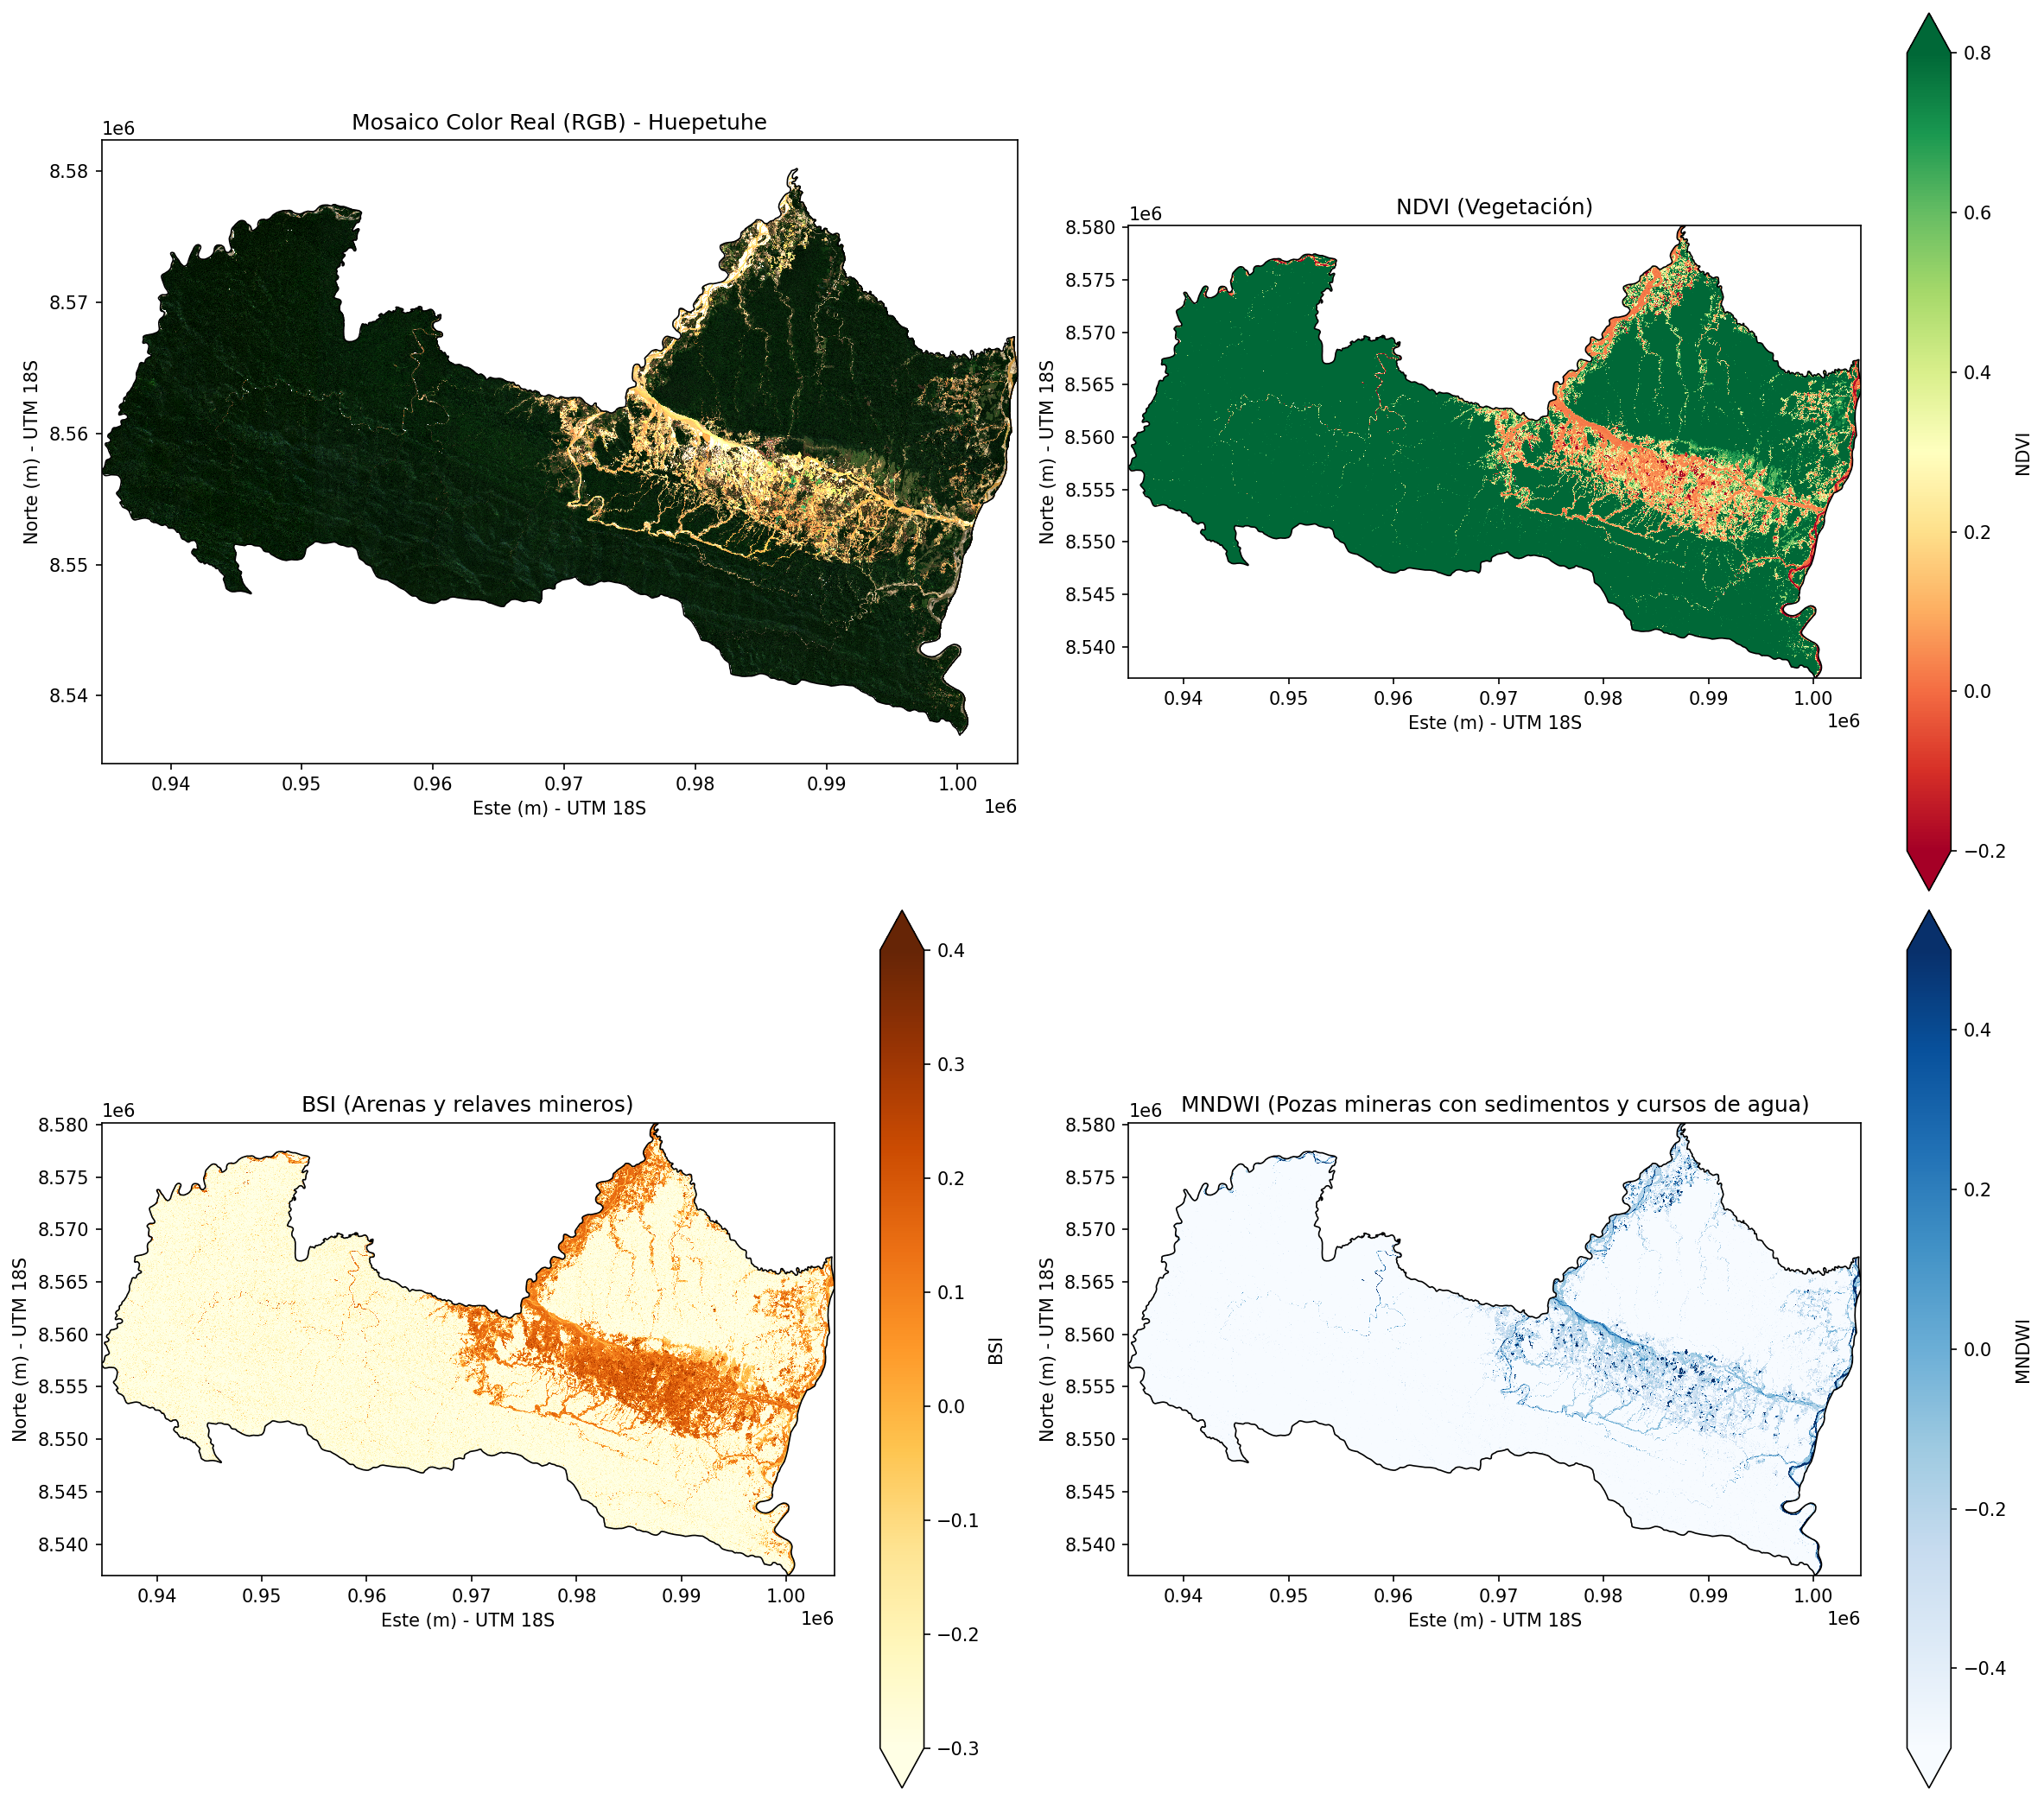

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 14), dpi=150)

# 1. Composición Color Real del mosaico
rgb = features_recortado.sel(band=["B04", "B03", "B02"])
rgb.plot.imshow(ax=axes[0, 0], robust=True)
axes[0, 0].set_title("Mosaico Color Real (RGB) - Huepetuhe")

# 2. NDVI
features_recortado.sel(band="NDVI").plot(
    ax=axes[0, 1], cmap="RdYlGn", vmin=-0.2, vmax=0.8, cbar_kwargs={"label": "NDVI"}
)
axes[0, 1].set_title("NDVI (Vegetación)")

# 3. BSI (Índice de Suelo Desnudo --> Resalta arenas y relaves mineros)
features_recortado.sel(band="BSI").plot(
    ax=axes[1, 0], cmap="YlOrBr", vmin=-0.3, vmax=0.4, cbar_kwargs={"label": "BSI"}
)
axes[1, 0].set_title("BSI (Arenas y relaves mineros)")

# 4. MNDWI (Pozas mineras con sedimentos y cursos de agua)
features_recortado.sel(band="MNDWI").plot(
    ax=axes[1, 1], cmap="Blues", vmin=-0.5, vmax=0.5, cbar_kwargs={"label": "MNDWI"}
)
axes[1, 1].set_title("MNDWI (Pozas mineras con sedimentos y cursos de agua)")

# Superponer el contorno del distrito en los 4 paneles
for ax in axes.flat:
    shp_utm.boundary.plot(ax=ax, color="black", linewidth=0.8)
    ax.set_xlabel("Este (m) - UTM 18S")
    ax.set_ylabel("Norte (m) - UTM 18S")

plt.tight_layout()
plt.savefig("Panel_Indices_Mineria_Huepetuhe.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()



In [ ]:
nombres_bandas = list(features_recortado.band.values)
features_recortado.attrs["long_name"] = nombres_bandas

# Guarda GeoTIFF
features_recortado.rio.to_raster("Huepetuhe_2025_Stack_12Bandas.tif", compress="LZW")